# RQ1 — Probability boxplots with paired-comparison brackets

Builds a combined RQ1 figure. For each (detector, model) cell, the boxplots show the detector's operational AI-probability per context: a detector failure is represented as probability 0 because it does not flag the description in use. Context contrasts are aligned by PR and tested with two-sided Wilcoxon signed-rank tests. Brackets show only comparisons significant after Benjamini--Hochberg correction across the 15 context pairs within that detector/model panel; labels report the matched-pairs rank-biserial correlation (`r_rb`), whose sign is context on the left minus context on the right.

Server-side candidate output: `outputs/figures_pdf/rq1_probability_boxplots_paired.pdf`. Copy it into the writing repository only after the cleaned-run integrity and statistical outputs have been reviewed.

In [1]:
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import paired_stats as PS

CSV_PATH = '../datasets/temperature_1/run_3_cleaned/detection_results.csv'
OUT_PDF = Path('outputs/figures_pdf/rq1_probability_boxplots_paired.pdf')
OUT_PDF.parent.mkdir(parents=True, exist_ok=True)

TOOLS = ['roberta', 'roberta-qa', 'zerogpt']
TOOL_LABELS = {
    'roberta': 'ChatGPT Detector RoBERTa',
    'roberta-qa': 'ChatGPT-QA Detector RoBERTa',
    'zerogpt': 'ZeroGPT',
}
MODELS = ['Qwen/Qwen2.5-72B-Instruct', 'gpt-5-mini-2025-08-07', 'meta-llama/llama-3.1-70b-instruct']
MODEL_LABELS = {
    'Qwen/Qwen2.5-72B-Instruct': 'Qwen2.5-72B',
    'gpt-5-mini-2025-08-07': 'GPT-5-mini',
    'meta-llama/llama-3.1-70b-instruct': 'Llama-3.1-70B',
}
MODEL_COLORS = {
    'Qwen/Qwen2.5-72B-Instruct': '#1f77b4',
    'gpt-5-mini-2025-08-07': '#ff7f0e',
    'meta-llama/llama-3.1-70b-instruct': '#2ca02c',
}

VARIATION_ORDER = ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
VARIATION_MAP = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File C.',
}
VARIATION_SHORT = ['Repo', 'Title', 'Diff', 'File', 'Issue', 'No-FC']  # x-axis tick labels

In [2]:
def as_bool(series):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)
    return series.astype(str).str.strip().str.lower().isin({'true', '1', 'yes'})

df = pd.read_csv(CSV_PATH)
ai = df[df['entry_type'] == 'ai'].copy()
ai['normalized_pr_id'] = ai['pr_id'].astype(str).str.strip()
if ai.duplicated(['normalized_pr_id', 'model', 'variation']).any():
    raise RuntimeError('Duplicate PR/model/context rows in RQ1 input')
print('AI rows loaded:', len(ai))
print('Variations:', sorted(ai['variation'].unique()))
print('Models:', sorted(ai['model'].unique()))

AI rows loaded: 5526
Variations: ['P-1', 'P-2', 'P-3', 'P-4', 'P-5', 'P-6']
Models: ['Qwen/Qwen2.5-72B-Instruct', 'gpt-5-mini-2025-08-07', 'meta-llama/llama-3.1-70b-instruct']


In [3]:
# Operational detector probability: a failed detector call did not flag the text.
# Precompute paired context tests per detector/model; each panel is one BH family.
pairwise_rows = []
for tool in TOOLS:
    prob_col = f'{tool}_ai_probability'
    success_col = f'{tool}_success'
    if prob_col not in ai or success_col not in ai:
        raise RuntimeError(f'Missing detector columns for {tool}')
    ai[f'{tool}_operational_probability'] = pd.to_numeric(ai[prob_col], errors='coerce')
    ai.loc[~as_bool(ai[success_col]), f'{tool}_operational_probability'] = 0.0
    operational_col = f'{tool}_operational_probability'
    for model in MODELS:
        for va, vb in itertools.combinations(VARIATION_ORDER, 2):
            a = ai[(ai['model'] == model) & (ai['variation'] == va)][['normalized_pr_id', operational_col]]
            b = ai[(ai['model'] == model) & (ai['variation'] == vb)][['normalized_pr_id', operational_col]]
            paired = PS.paired_test_from_frames(
                a, b, operational_col, key='normalized_pr_id'
            )
            pairwise_rows.append({
                'tool': tool,
                'model': model,
                'va': va,
                'vb': vb,
                'sign': 'positive means va has higher probability than vb',
                **paired,
            })
pairwise_df = PS.apply_fdr_by(
    pd.DataFrame(pairwise_rows), by=['tool', 'model'], pcol='p'
)
pairwise_df['Sig'] = pairwise_df['adj_p'].apply(PS.sig_mark)
print('Total paired context comparisons:', len(pairwise_df))
print('BH-significant comparisons:', int(pairwise_df['sig'].sum()))
pairwise_df.head()

Total paired context comparisons: 135
BH-significant comparisons: 107


,tool,model,va,vb,sign,n,median_human,median_ai,cliffs_delta,rank_biserial,wilcoxon_stat,p,magnitude,adj_p,sig,Sig
0,roberta,Qwen/Qwen2.5-72B-Instruct,P-1,P-2,positive means va has higher probability than vb,308,0.006679,0.236481,-0.116967,-0.378756,14306.0,1.101036e-08,Negligible,2.752589e-08,True,***
1,roberta,Qwen/Qwen2.5-72B-Instruct,P-1,P-3,positive means va has higher probability than vb,308,0.006679,0.004718,0.007295,0.062397,22164.0,3.433437e-01,Negligible,4.291796e-01,False,n.s.
2,roberta,Qwen/Qwen2.5-72B-Instruct,P-1,P-4,positive means va has higher probability than vb,302,0.006679,0.062899,-0.233959,-0.318864,15582.0,1.564261e-06,Small,3.351987e-06,True,***
3,roberta,Qwen/Qwen2.5-72B-Instruct,P-1,P-5,positive means va has higher probability than vb,308,0.006679,0.022495,-0.047521,-0.055100,22482.0,4.019580e-01,Negligible,4.637977e-01,False,n.s.
4,roberta,Qwen/Qwen2.5-72B-Instruct,P-1,P-6,positive means va has higher probability than vb,308,0.006679,0.008054,-0.032910,0.021015,23293.0,7.492316e-01,Negligible,8.027481e-01,False,n.s.


In [4]:
def draw_bracket(ax, x1, x2, y, label, color='black'):
    """Draw a horizontal bracket from x1 to x2 at height y with `label` on top."""
    tick = 0.022
    ax.plot([x1, x1, x2, x2], [y - tick, y, y, y - tick], lw=0.7, c=color, clip_on=False)
    ax.text((x1 + x2) / 2, y + 0.012, label, ha='center', va='bottom', fontsize=10, color=color, clip_on=False)

MAX_BRACKETS_PER_PANEL = 5  # cap clutter; ranked by |matched rank-biserial|

def plot_panel(ax, ai_subset, tool, model, deltas_for_cell, show_x=True, show_y=True):
    prob_col = f'{tool}_operational_probability'
    data_per_var = []
    counts = []
    for v in VARIATION_ORDER:
        vals = ai_subset[(ai_subset['model'] == model) & (ai_subset['variation'] == v)][prob_col].dropna().values
        data_per_var.append(vals)
        counts.append(len(vals))

    color = MODEL_COLORS[model]
    positions = np.arange(len(VARIATION_ORDER))
    ax.boxplot(
        data_per_var,
        positions=positions,
        widths=0.55,
        patch_artist=True,
        showfliers=True,
        flierprops=dict(marker='.', markersize=2, alpha=0.35),
        medianprops=dict(color='black', lw=1.0),
        boxprops=dict(facecolor=color, alpha=0.65, edgecolor='black', lw=0.7),
        whiskerprops=dict(color='black', lw=0.7),
        capprops=dict(color='black', lw=0.7),
    )

    ax.set_ylim(-0.02, 2.05)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xticks(positions)
    ax.set_xticklabels(VARIATION_SHORT, fontsize=12, rotation=30, ha='right')
    if not show_x:
        ax.set_xticklabels([])
    if show_y:
        ax.set_ylabel('AI probability', fontsize=12)
    ax.tick_params(axis='both', labelsize=12)
    ax.grid(axis='y', linestyle=':', alpha=0.4)
    ax.axhline(0.5, color='gray', linestyle='--', lw=0.6, alpha=0.55)

    # BH-significant paired contrasts, capped at MAX_BRACKETS_PER_PANEL.
    sig = deltas_for_cell[deltas_for_cell['sig']].copy()
    sig['abs_effect'] = sig['rank_biserial'].abs()
    sig = sig.sort_values('abs_effect', ascending=False).head(MAX_BRACKETS_PER_PANEL)
    n_shown = len(sig)
    n_total = int(deltas_for_cell['sig'].sum())

    base_y = 1.08
    step = 0.17
    for i, (_, row) in enumerate(sig.iterrows()):
        x1 = VARIATION_ORDER.index(row['va'])
        x2 = VARIATION_ORDER.index(row['vb'])
        y = base_y + i * step
        label = f"r={row['rank_biserial']:+.2f}{row['Sig']}"
        draw_bracket(ax, x1, x2, y, label)

    # If we capped, note the omitted count
    if n_total > n_shown:
        ax.text(
            0.98, 0.985, f"+{n_total - n_shown} more significant",
            transform=ax.transAxes, ha='right', va='top', fontsize=7,
            color='dimgray', style='italic',
        )

    # Per-context n at the bottom — use pixel offset so it sits *below* rotated x-tick labels
    # (offset depends on whether tick labels are shown for this row)
    yoffset_pts = -38 if show_x else -8
    for x, n in zip(positions, counts):
        ax.annotate(
            f'n={n}',
            xy=(x, 0), xycoords=('data', 'axes fraction'),
            xytext=(0, yoffset_pts), textcoords='offset points',
            ha='center', va='top', fontsize=9, color='dimgray',
            annotation_clip=False,
        )

Saved: outputs/figures_pdf/rq1_probability_boxplots_paired.pdf


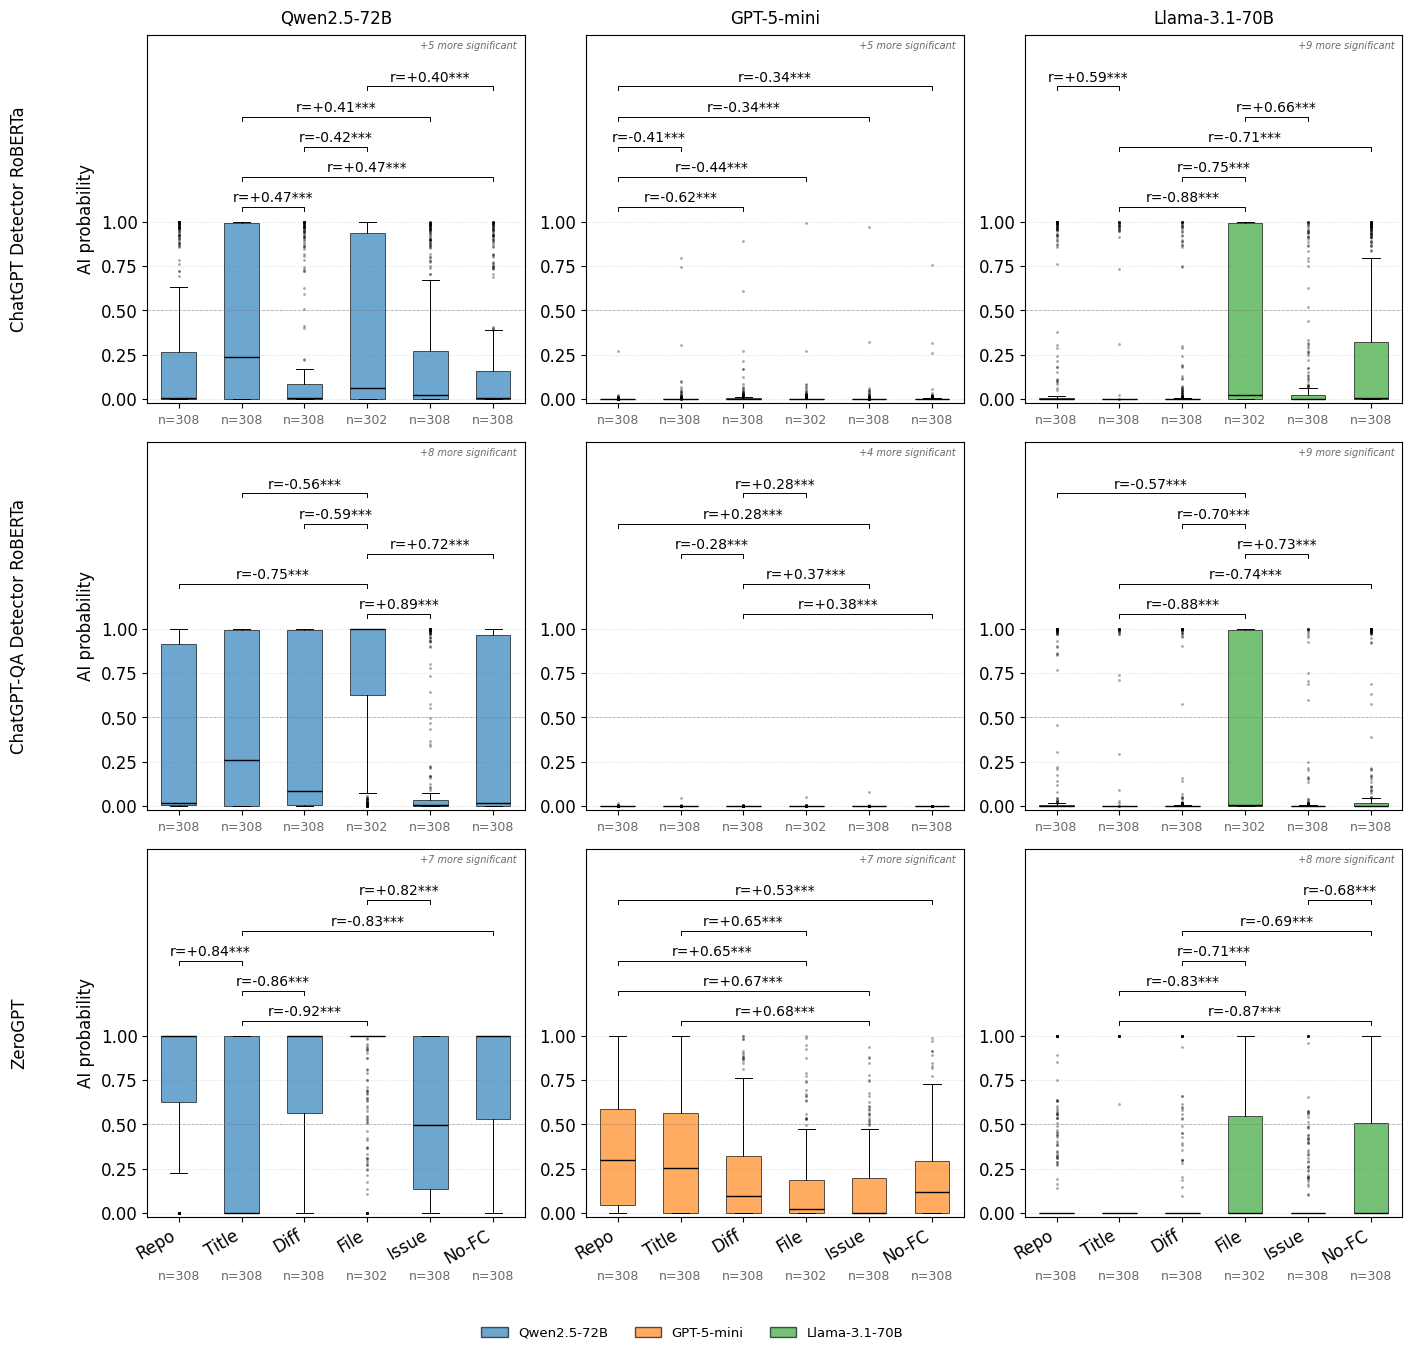

In [5]:
fig, axes = plt.subplots(
    nrows=len(TOOLS), ncols=len(MODELS),
    figsize=(14.5, 13.5), sharey=False,
)

for r, tool in enumerate(TOOLS):
    for c, model in enumerate(MODELS):
        ax = axes[r, c]
        deltas = pairwise_df[(pairwise_df['tool'] == tool) & (pairwise_df['model'] == model)]
        plot_panel(
            ax, ai, tool, model, deltas,
            show_x=(r == len(TOOLS) - 1),
            show_y=(c == 0),
        )
        if r == 0:
            ax.set_title(MODEL_LABELS[model], fontsize=12, pad=8)
        if c == 0:
            ax.text(
                -0.34, 0.5, TOOL_LABELS[tool],
                transform=ax.transAxes, rotation=90, va='center', ha='center',
                fontsize=12,
            )

legend_handles = [
    Patch(facecolor=MODEL_COLORS[m], alpha=0.65, edgecolor='black', label=MODEL_LABELS[m])
    for m in MODELS
]
fig.legend(
    handles=legend_handles,
    loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.005),
    frameon=False, fontsize=9.5,
)

fig.tight_layout(rect=[0.03, 0.035, 1, 1.0])
fig.savefig(OUT_PDF, bbox_inches='tight')
fig.savefig(str(OUT_PDF).replace('.pdf', '.png'), dpi=170, bbox_inches='tight')
print('Saved:', OUT_PDF)
plt.show()

In [6]:
# Diagnostics: how many brackets per panel?
diag = (
    pairwise_df[pairwise_df['sig']]
    .groupby(['tool', 'model'])
    .size()
    .reset_index(name='n_brackets')
    .sort_values('n_brackets', ascending=False)
)
diag

,tool,model,n_brackets
2,roberta,meta-llama/llama-3.1-70b-instruct,14
5,roberta-qa,meta-llama/llama-3.1-70b-instruct,14
8,zerogpt,meta-llama/llama-3.1-70b-instruct,13
3,roberta-qa,Qwen/Qwen2.5-72B-Instruct,13
6,zerogpt,Qwen/Qwen2.5-72B-Instruct,12
7,zerogpt,gpt-5-mini-2025-08-07,12
0,roberta,Qwen/Qwen2.5-72B-Instruct,10
1,roberta,gpt-5-mini-2025-08-07,10
4,roberta-qa,gpt-5-mini-2025-08-07,9
